<a href="https://colab.research.google.com/github/Krzyker/DataScienceColabs/blob/main/cse351_hw3_brachowski_krzysztof_116565000.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **New York City AirBnB Data Analysis Project**

Krzysztof Brachowski

---
This assignment uses data available at [this kaggle repository](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data).

In [2]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#reading in the data
data = pd.read_csv('/content/AB_NYC_2019.csv')
data.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


Using the describe() function, I notice some anomalies in the data that should be cleaned up. For example, there is an AirBnB with a minmum_nights value of 1250. There are also listings with a price value of 0. I will utilize seaborn functions to plot data and spot anomalies easier.

Text(0.5, 1.0, 'Data Munging Aide')

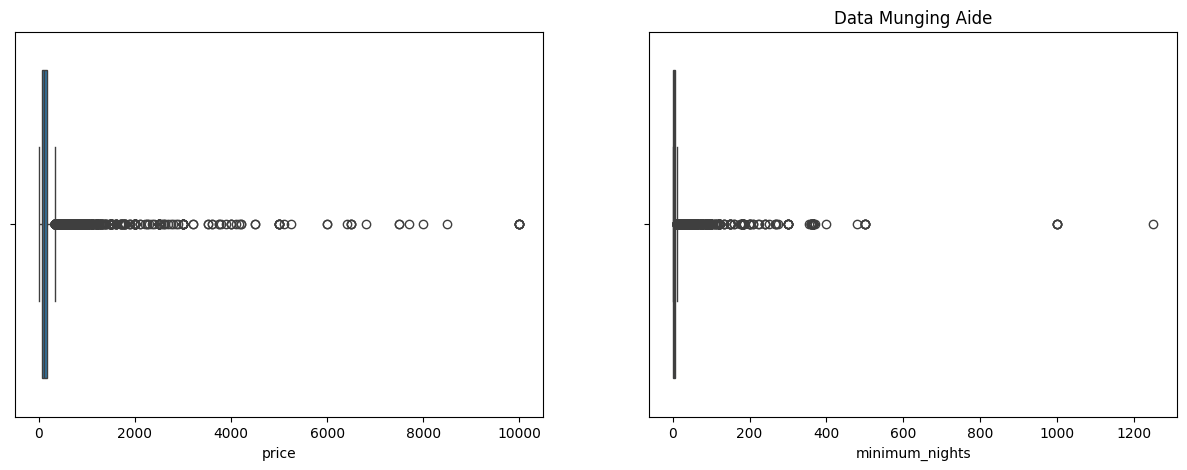

In [3]:
fig, axes = plt.subplots(1, 2, figsize = (15,5)) #using matplotlib to display charts side by side

# unedited data charts
sns.boxplot(x=data['price'], ax = axes[0])
sns.boxplot(x=data['minimum_nights'], ax = axes[1])
plt.title("Data Munging Aide")

For the purposes of this data analysis, I will get rid of data with a minimum price of 0, and data with minimum_nights greater than 100. Importantly, I am not adressing the extreme outliers in price, since I believe they will have important bearing on price difference per neighbourhood.

                 id       host_id      latitude     longitude         price  \
count  4.871000e+04  4.871000e+04  48710.000000  48710.000000  48710.000000   
mean   1.902923e+07  6.768092e+07     40.728926    -73.952116    152.337323   
std    1.097921e+07  7.863728e+07      0.054537      0.046189    237.261250   
min    2.539000e+03  2.438000e+03     40.499790    -74.244420     10.000000   
25%    9.477162e+06  7.835312e+06     40.690060    -73.983030     69.000000   
50%    1.969462e+07  3.085086e+07     40.723040    -73.955660    106.000000   
75%    2.915608e+07  1.074344e+08     40.763130    -73.936170    175.000000   
max    3.648724e+07  2.743213e+08     40.913060    -73.712990  10000.000000   

       minimum_nights  number_of_reviews  reviews_per_month  \
count    48710.000000       48710.000000       38744.000000   
mean         6.155471          23.317430           1.375268   
std         10.049833          44.573394           1.681299   
min          1.000000           0.00

Text(0.5, 1.0, 'After Data Munging')

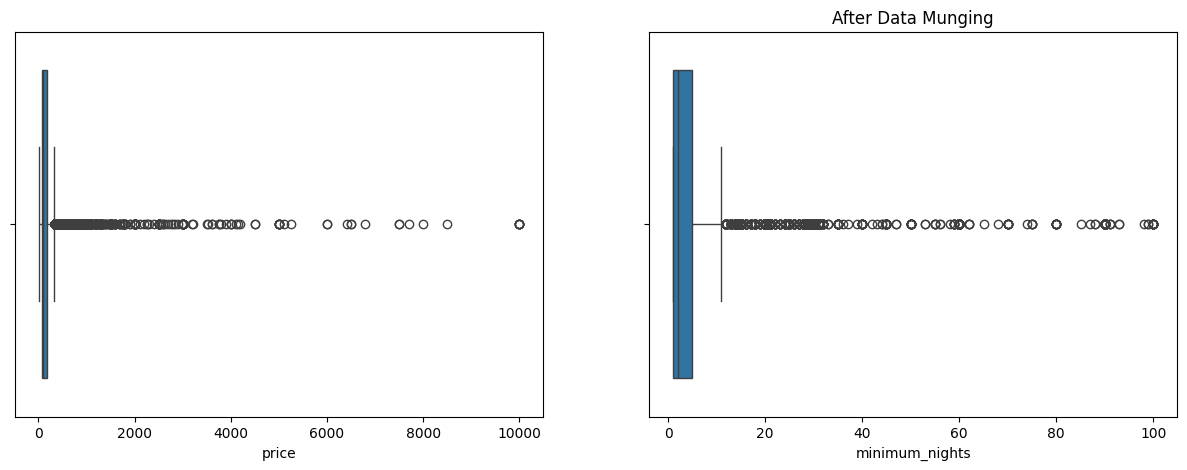

In [4]:
data = data[data['price'] > 0]
data = data[data['minimum_nights'] <= 100]
data.reset_index() # brings back sequential indexing by patching holes

#re-displaying
print(data.describe())
fig, axes = plt.subplots(1, 2, figsize = (15,5))
sns.boxplot(x=data['price'], ax = axes[0])
sns.boxplot(x=data['minimum_nights'], ax = axes[1])
plt.title("After Data Munging")

# **Neighbourhood Analysis**
---
We will examine how the prices of AirBnBs change with change in neighbourhood. Out of neighbourhoods with over 5 listings, we will find the top 5 and bottom 5 neighborhoods by median AirBnB price.

In [5]:
# calculating medians
medians = data.groupby('neighbourhood')['price'].median()
print(medians.sort_values())

neighbourhood
Concord            34.5
Castle Hill        39.0
Corona             40.0
Hunts Point        40.0
New Dorp Beach     40.0
                  ...  
NoHo              250.0
Neponsit          274.0
Tribeca           293.0
Woodrow           700.0
Fort Wadsworth    800.0
Name: price, Length: 221, dtype: float64


In [6]:
# As per requirements of the assignment, now we print just the neighborhoods with more than 5 listings
counts = data['neighbourhood'].value_counts() # how many per
print(medians[counts >= 5].sort_values())

neighbourhood
Concord                34.5
Castle Hill            39.0
Corona                 40.0
Hunts Point            40.0
New Dorp Beach         40.0
                      ...  
Financial District    200.0
Midtown               210.0
Flatiron District     225.0
NoHo                  250.0
Tribeca               293.0
Name: price, Length: 195, dtype: float64


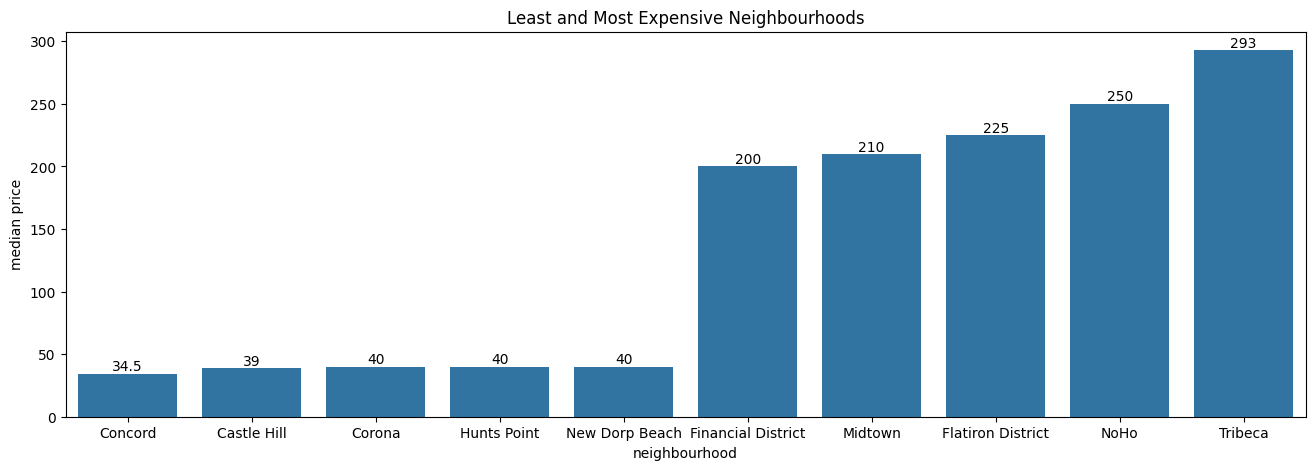

In [7]:
# Plotting the trends
temp = medians[counts >= 5].sort_values()
plt.figure(figsize = (16,5))
ax = sns.barplot(pd.concat([temp.head(5), temp.tail(5)]))
ax.bar_label(ax.containers[0]) # labeling bars on top
plt.ylabel('median price')
plt.title("Least and Most Expensive Neighbourhoods")
plt.show()

**Neighbourhood Analysis Takeaways**

Clearly, there exists a large difference in the price of AirBnB between neighbourhoods. Neighbourhoods closer to areas of interest, or generally in wealthier areas, such as Midtown and the Financial District, have AirBnB's with up to **8 times** as large median price as the poorer areas. The cheapest neighbourhoods tend to be ones furthest from the center of Manhattan. For example, as demonstrated by the lowest 5 medians, Castle Hill and Corona. They are located in the upper Bronx and eastern Queens respectively.

# **Pearson Correlation Analysis of Interesting Features**
---
We will perform Pearson Correlation Analysis of all of the numeric features besides longitude and latitude. This includes **price, minimum_nights, number_of_reviews, reviews_per_month,** and **availability_365**.   

Text(0.5, 1.0, 'Pearson Heatmap')

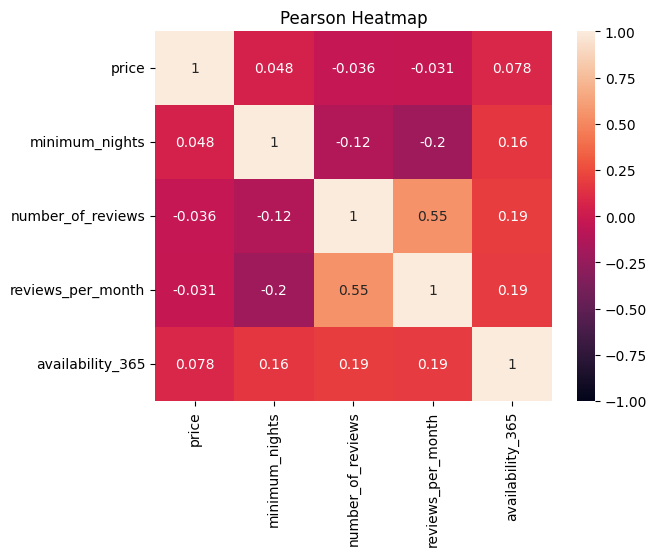

In [8]:
subset = data[['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'availability_365']].dropna() # dropping null values

# actual calculation
correlation_matrix = subset.corr(method='pearson')

# displaying the heatmap
sns.heatmap(correlation_matrix, annot = True, vmin = -1) # annot prints the values on the boxes, vmin makes the lower bound of colors -1 for pearson
plt.title("Pearson Heatmap")

The greatest correlation as found by the pearson correlation appears to be between **reviews_per_month** and **number_of_reviews**. It is intuitive that an AirBnB with a high rate of people leaving reviews on it has a high amount of total reviews and vice versa. A result that I found particularly interesting is the **-0.2** correlation between **minimum_nights** and **reviews_per_month**. It makes sense that an AirBnB which has a greater shortest stay requirement gets less visitors throughout the month and therefore has less opportunities to get reviews.

# **Latitude and Longitude Analaysis**
---
Plotting a scatterplot based on AirBnB latitude and longitude. The first scatterplot includes all of the boroughs labeled by color to distinguish, with normalization of axes to make the city appear as on a map. The second scatterplot displays the AirBnBs with a color gradient reflecting the respective price.

Text(0.5, 1.0, 'AirBnBs in NYC')

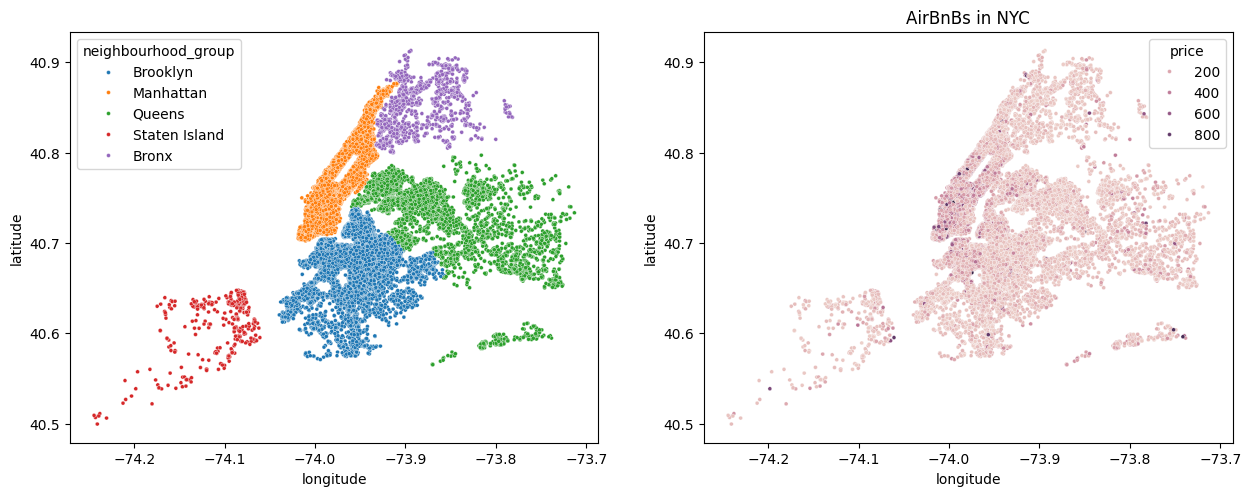

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15,6))
sns.scatterplot(data, x='longitude', y='latitude', hue='neighbourhood_group', ax=axes[0], s = 8) # s parameter makes the points smaller so trends are more apparent
sns.scatterplot(data[data['price'] < 1000], x='longitude', y='latitude', hue='price', ax=axes[1], s = 8)
axes[0].set_aspect('equal')
axes[1].set_aspect('equal')
plt.title("AirBnBs in NYC")

From these scatterplots, it is clearly apparent that Manhattan is the most expensive borough when it comes to AirBnB prices. It has the highest frequency of darker dots, which becomes even more apparent as we bring the price limit down to 500. However, for the purposes of this assignment, it is left at 1000.

# **Word Cloud**
---


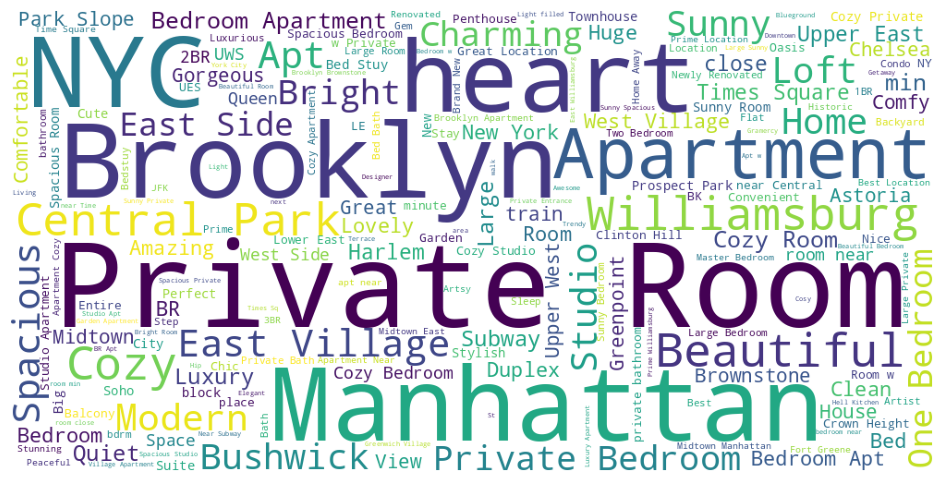

In [10]:
from wordcloud import WordCloud as wc, STOPWORDS # stop words omit filler

plt.figure(figsize=(12,6))
string = " ".join(name for name in data['name'].dropna())
wordcloud = wc(width = 1000, height = 500, stopwords = STOPWORDS, background_color='white').generate(string)
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

# **Busy Host Analysis**
---
In this section, we will find which areas of NYC have the busiest AirBnB hosts, and what are the reasons why. We will support these insights with data from plots and correlations.

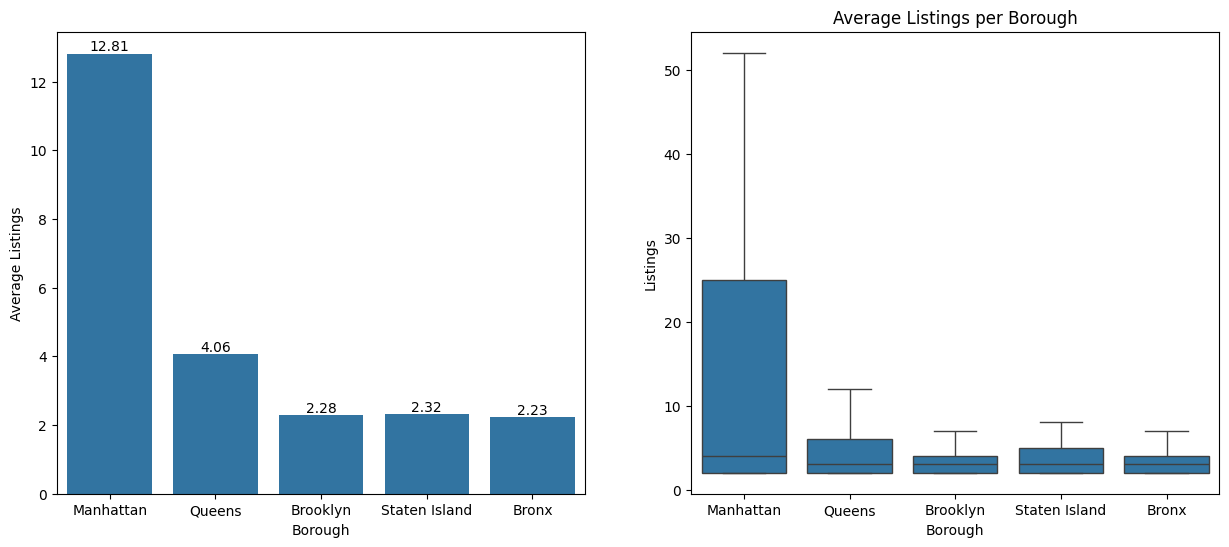

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15,6))
order = ['Manhattan', 'Queens', 'Brooklyn', 'Staten Island', 'Bronx']
ax = sns.barplot(data, x='neighbourhood_group', y='calculated_host_listings_count', errorbar=None, ax=axes[0], order=order)
ax.bar_label(ax.containers[0], fmt = '%.2f')
axes[0].set_ylabel("Average Listings")
axes[0].set_xlabel("Borough")
sns.boxplot(data[data['calculated_host_listings_count'] > 1], x='neighbourhood_group', y='calculated_host_listings_count', showfliers=False, order=order)
axes[1].set_ylabel("Listings")
axes[1].set_xlabel("Borough")
plt.title("Average Listings per Borough")
plt.show()

Before analysis, it is important to mention that the box plot graph on the right is data edited to only include data on hosts with **more than 1 listing**. Additionally, **showfliers=False** which  implies that outliers are not shown. From the displayed bar graph and boxplot, the trend is apparent. Clearly, AirBnB owners in Manhattan have on average many more listings than in the other boroughs. Queens is in a far second place while the other three boroughs are relatively close in average listings per landlord.

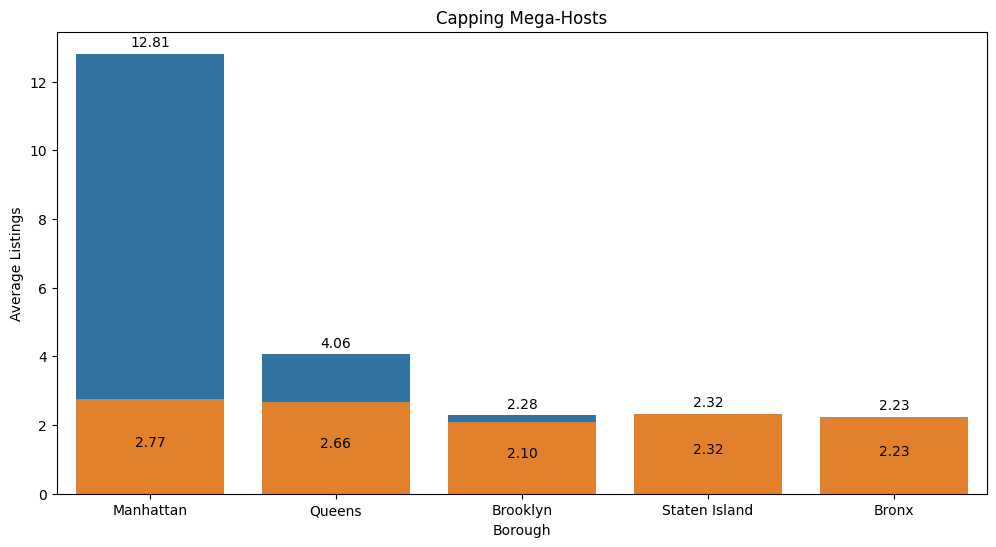

In [12]:
plt.figure(figsize=(12,6))
ax = sns.barplot(data, x='neighbourhood_group', y='calculated_host_listings_count', errorbar=None, order=order)
sns.barplot(data[data['calculated_host_listings_count'] < 50], x='neighbourhood_group', y='calculated_host_listings_count', errorbar=None, ax=ax, order=order)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)
ax.bar_label(ax.containers[1], fmt='%.2f', padding=3, label_type='center')
plt.title("Capping Mega-Hosts")
ax.set_ylabel("Average Listings")
ax.set_xlabel("Borough")
plt.show()

I was interested in further investigating whether this difference is examplified through a majority of landlords in Manhattan or just the far outliers. This figure demonstrates in orange the average amount of listings per landlord in each Borough, **excluding landlords with over 50 AirBnBs**. This graph is really insightful as it tells us that the difference between average listings per borough is probably attributed to mega-hosts with listings in the hundreds. Another thing worth noting is the consistancy of Brooklyn's, Statend Island's, and the Bronx's average listings after removing landlords with over 50 AirBnBs. Clearly, these mega-hosts are drawn to Manhattan, likely due to it being the most expensive and desirable borough. We can back up this assertment with data from our Pearson Correlation heat maps.

Text(0.5, 1.0, 'Manhattan Pearson Heatmap')

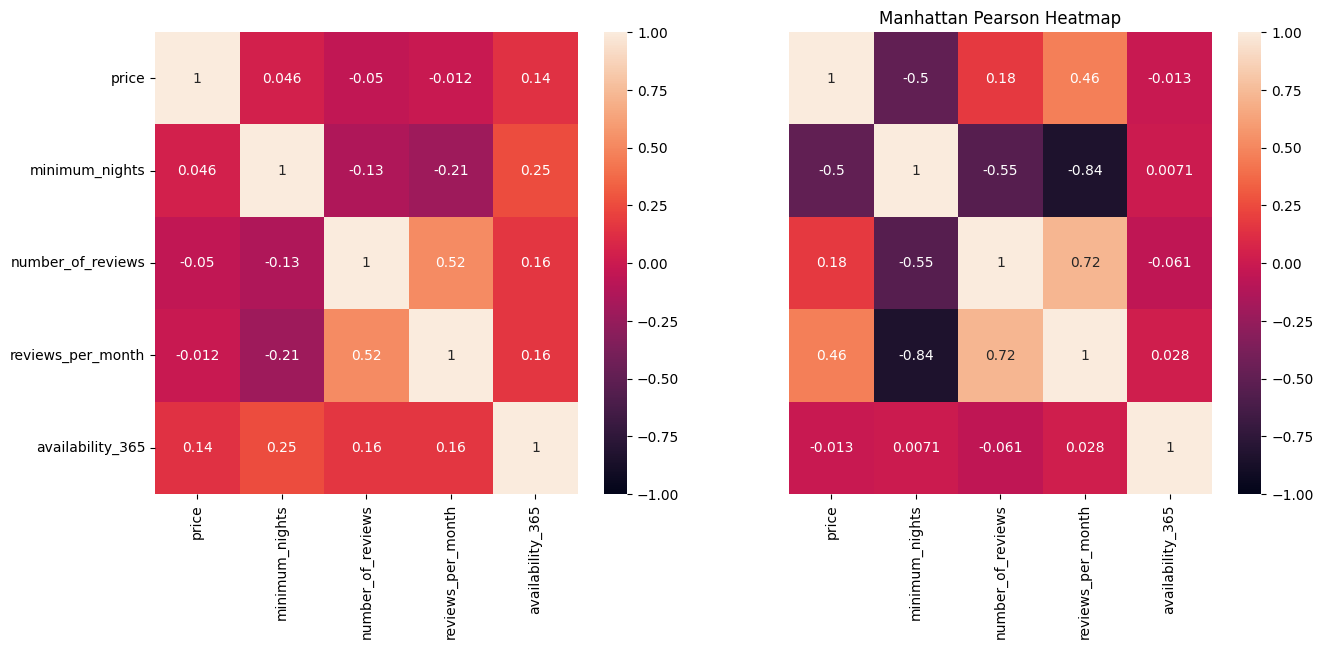

In [13]:
#Taking JUST Manhattan
fig, axes = plt.subplots(1, 2, figsize=(15,6))
subset = data[data['neighbourhood_group'] == 'Manhattan'][['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'availability_365']].dropna()
correlation_matrix = subset.corr(method='pearson')
sns.heatmap(correlation_matrix, annot = True, vmin = -1, ax = axes[0])
subset2 = data[(data['neighbourhood_group'] == 'Manhattan') & (data['calculated_host_listings_count'] > 50)][['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'availability_365']].dropna()
correlation_matrix = subset2.corr(method='pearson')
sns.heatmap(correlation_matrix, annot = True, vmin = -1, ax = axes[1], yticklabels=False)
plt.title("Manhattan Pearson Heatmap")

The heatmap on the left demonstrates pearson correlations between variables for all Manhattan AirBnBs while the chart on the right demonstrates pearson correlation rates between variables for Manhattan AirBnBs from landlords with over 50 listings. The fascinating number here comes in the relationship between price and availability. For all AirBnBs in Manhattan, **r=0.14** between price and availability_365. This weakly implies that as AirBnBs get more expensive in Manhattan, their availability generally increases. This is contrasting the **r=-0.013** in the second heatmap, which implies that for very successful landlords in Manhattan, a price increase is uncorrelated, or very weakly negatively correlated, with availability. These two data inferences show us that successful landlords can sell more expensive AirBnBs better than the average landlord in Manhattan, making it the borough they are drawn to.

# **Best AirBnB Spot**
---
In this section, I will use availability and price data to find the best (and worst) locations in NYC to open up an AirBnB. I assigned a score to every AirBnB in NYC with the formula **log(price * (365 - availability) + 1)**. I wanted to base the best AirBnB locations on just two variables - price and availability. Thus, these two values get multiplied. Additionally, I had apply a logarithm to normalize the extreme values of score achieved by extremely expensive AirBnBs. The 1 is added so there are no domain issues with the log function. Refer to code for additional bounds emplaced on the data to achieve a clearer map.

Text(0.5, 1.0, 'Best AirBnB Locations (NYC/Manhattan)')

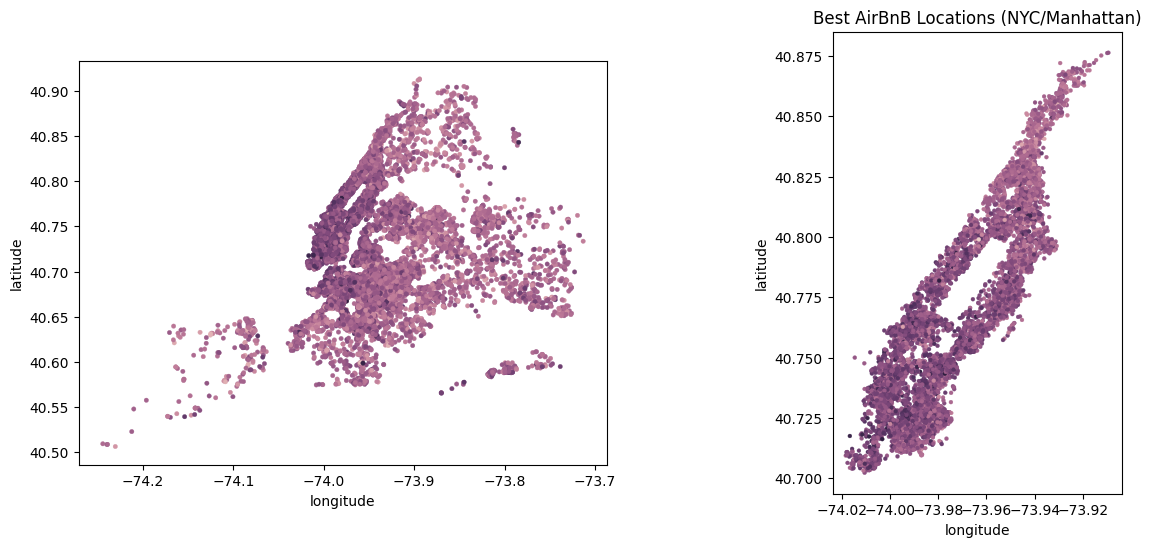

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15,6))
data['score'] = np.log10(data['price'] * (365-data['availability_365']) + 1)
sns.scatterplot(data[(data['price'] < 1000) & (10 < data['availability_365']) & (data['availability_365'] < 300)], x='longitude', y='latitude', hue='score', ax=axes[0], s = 10, legend=False, edgecolor=None)
sns.scatterplot(data[(data['neighbourhood_group'] == 'Manhattan') & (data['price'] < 1000)  & (10 < data['availability_365']) & (data['availability_365'] < 300)], x='longitude', y='latitude', hue='score', ax=axes[1], s = 8, legend=False, edgecolor=None)
axes[0].set_aspect('equal')
axes[1].set_aspect('equal')
plt.title("Best AirBnB Locations (NYC/Manhattan)")

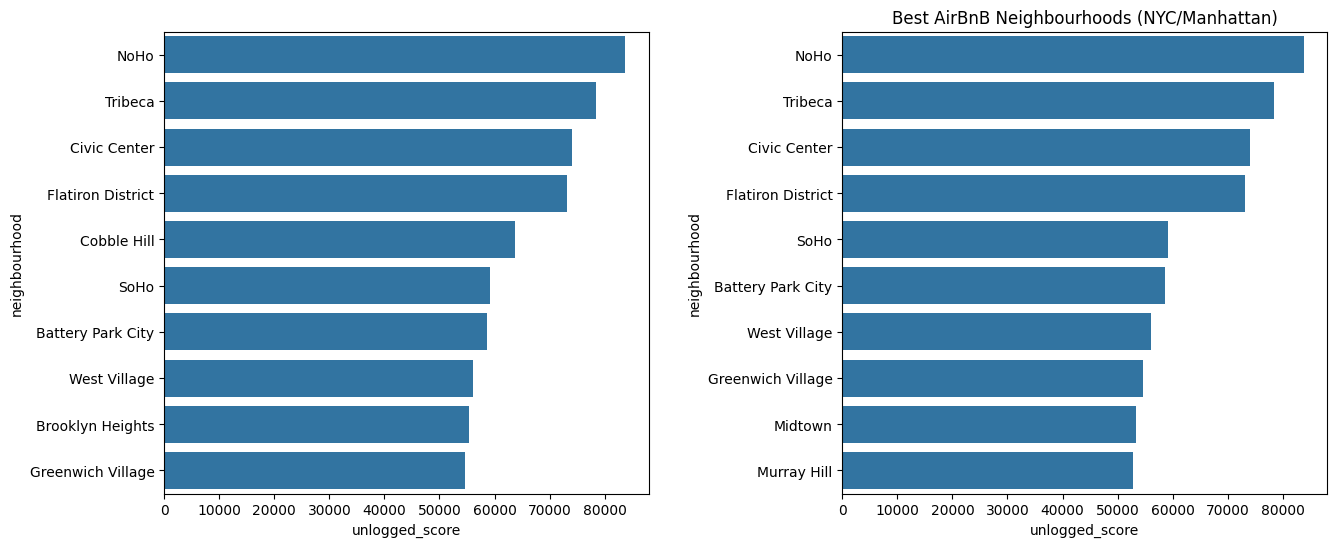

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15,6))
#We will use UNLOGGED score for this so that there aren't mane ties at the top
data['unlogged_score'] = data['price'] * (365-data['availability_365'])
conditions = (data['price'] < 1000) & (10 < data['availability_365']) & (data['availability_365'] < 300) & (data.groupby('neighbourhood')['neighbourhood'].transform('count') >= 10)
top_10 = data[conditions].groupby('neighbourhood', as_index=False)['unlogged_score'].mean().sort_values(by='unlogged_score', ascending=False).head(10)
top_10m = data[conditions & (data['neighbourhood_group'] == 'Manhattan')].groupby('neighbourhood', as_index=False)['unlogged_score'].mean().sort_values(by='unlogged_score', ascending=False).head(10)
sns.barplot(data=top_10, x='unlogged_score', y='neighbourhood', ax=axes[0])
sns.barplot(data=top_10m, x='unlogged_score', y='neighbourhood', ax=axes[1])
plt.subplots_adjust(wspace=0.4) # Add space between plots
plt.title("Best AirBnB Neighbourhoods (NYC/Manhattan)")
plt.show()

With similar data editing as applied in the previous step, we can see the top neighbourhoods to start leasing AirBnBs in NYC. Notably, the top 7 neighbourhoods to lease and AirBnB in Manhattan appear on the top 10 neighbourhoods in NYC list. This further affirms my suspicion from the previous sections that Manhattan is the best place to lease an AirBnB.